In [24]:
import os
import pandas as pd
from cluster_weather_years.constants import BASE_INPUT, BASE_OUTPUT, HYDROLOGICAL_YEARS
from cluster_weather_years.helper_functions import build_df_from_modelyears
from ot import sliced_wasserstein_distance
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm


In [2]:
# load reference

DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_INPUT,
    "preprocessed_dataframes/df_prod_demand_daily_all_countries_with_hydro_scaled_demand.parquet",
)

VARS_TO_MATCH = [
    "NL_OFF_prod",
    "NL_ON_prod",
    "NL_SOLAR_prod",
    "NL_Demand",
    "NL_Residual_load",
]
df_daily = pd.read_parquet(DF_PROD_DEMAND_FNAME)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year in @HYDROLOGICAL_YEARS")
df_daily = df_daily.set_index(["model", "Date"])

vars_non_nan = [var for var in VARS_TO_MATCH if not df_daily[var].isna().all()]
df_ref = df_daily[["Hydrological_year", "Calendar_year"] + VARS_TO_MATCH].reset_index()

In [3]:
# load results

RUNNAME = "run_NL_30y_20260121_1726"
fname_results = os.path.join(BASE_OUTPUT, RUNNAME, "all_year_selections_scored.csv")
df_results = pd.read_csv(fname_results, index_col=0).sort_values("wasserstein")

In [4]:
df_best = build_df_from_modelyears(df_ref, eval(df_results.iloc[0]["model_years"]))[
    VARS_TO_MATCH
].to_numpy()
df_mid = build_df_from_modelyears(
    df_ref, eval(df_results.iloc[len(df_results) // 2]["model_years"])
)[VARS_TO_MATCH].to_numpy()
df_worst = build_df_from_modelyears(df_ref, eval(df_results.iloc[-1]["model_years"]))[
    VARS_TO_MATCH
].to_numpy()

df_ref_np = df_ref[VARS_TO_MATCH].to_numpy()

In [25]:
# Define projection counts to test
projection_counts = [10, 25, 50, 100, 200, 500, 1000]
n_repeats = 30  # Number of times to repeat each projection count

# results_projection = {"best": [], "mid": [], "worst": []}
results_projection = []
data_dict = {"best": df_best, "mid": df_mid, "worst": df_worst}

for n_proj in projection_counts:
    print(f"Processing n_proj={n_proj}...")
    for key, df_data in data_dict.items():
        print(f"  Data type: {key}")
        scores = []
        for _ in tqdm(range(n_repeats)):
            swd = sliced_wasserstein_distance(df_data, df_ref_np, n_projections=n_proj)
            scores.append(swd)

        results_projection.append(
            {
                "data_type": key,
                "n_projections": n_proj,
                "mean": np.mean(scores),
                "std": np.std(scores),
                "min": np.min(scores),
                "max": np.max(scores),
                "scores": scores,
            }
        )

df_projection = pd.DataFrame(results_projection)

Processing n_proj=10...
  Data type: best


  0%|          | 0/30 [00:00<?, ?it/s]

  Data type: mid


  0%|          | 0/30 [00:00<?, ?it/s]

  Data type: worst


...

  0%|          | 0/30 [00:00<?, ?it/s]

  Data type: mid


  0%|          | 0/30 [00:00<?, ?it/s]

  Data type: worst


  0%|          | 0/30 [00:00<?, ?it/s]

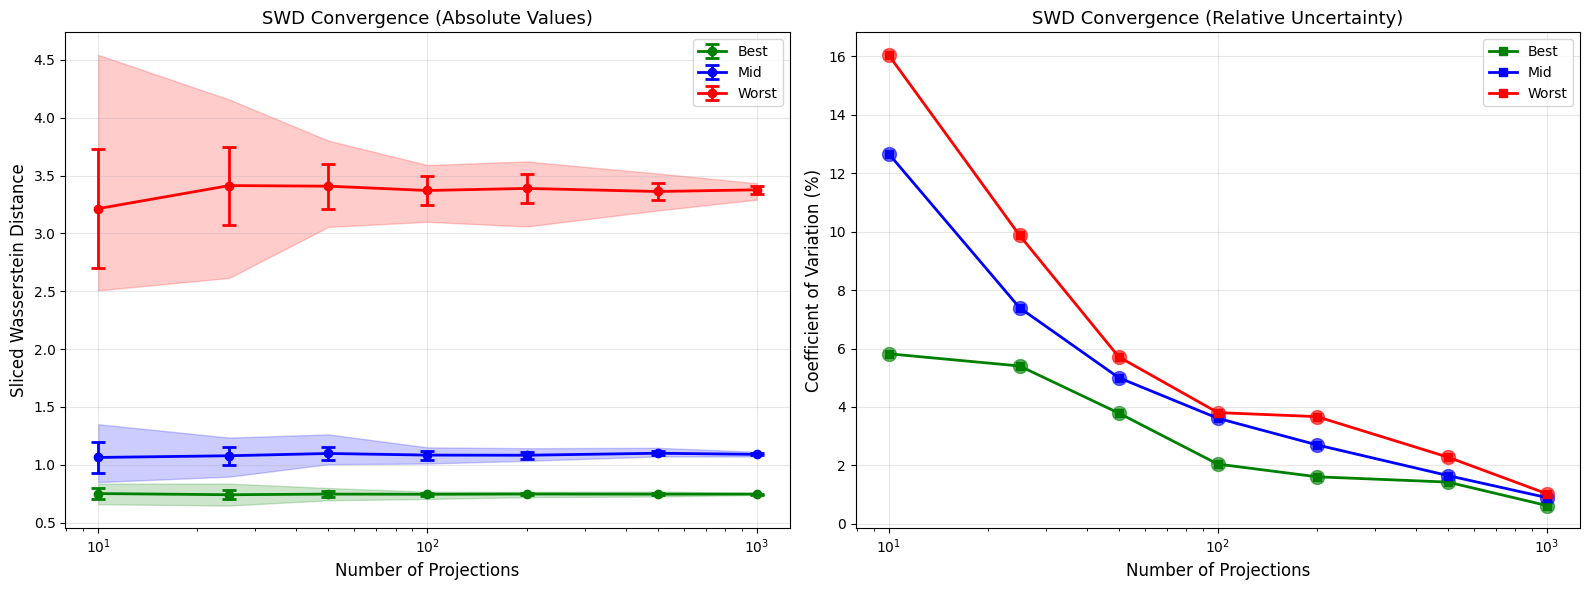

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for key, color in [("best", "green"), ("mid", "blue"), ("worst", "red")]:
    n_projs = [r["n_projections"] for r in results_projection if r["data_type"] == key]
    means = [r["mean"] for r in results_projection if r["data_type"] == key]
    stds = [r["std"] for r in results_projection if r["data_type"] == key]
    mins = [r["min"] for r in results_projection if r["data_type"] == key]
    maxs = [r["max"] for r in results_projection if r["data_type"] == key]

    # Calculate coefficient of variation (CV as percentage)
    cvs = [(s / m * 100) for m, s in zip(means, stds)]

    # Plot absolute values with error bars for std
    ax1.errorbar(
        n_projs,
        means,
        yerr=stds,
        marker="o",
        label=f"{key.capitalize()}",
        color=color,
        linewidth=2,
        capsize=5,
        capthick=2,
    )
    ax1.fill_between(
        n_projs,
        mins,
        maxs,
        color=color,
        alpha=0.2,
    )

    # Plot coefficient of variation
    ax2.plot(
        n_projs, cvs, marker="s", label=f"{key.capitalize()}", color=color, linewidth=2
    )
    ax2.scatter(n_projs, cvs, s=100, color=color, alpha=0.6)

ax1.set_xscale("log")
ax1.set_xlabel("Number of Projections", fontsize=12)
ax1.set_ylabel("Sliced Wasserstein Distance", fontsize=12)
ax1.set_title("SWD Convergence (Absolute Values)", fontsize=13)
ax1.legend(loc="best")
ax1.grid(True, alpha=0.3)

ax2.set_xscale("log")
ax2.set_xlabel("Number of Projections", fontsize=12)
ax2.set_ylabel("Coefficient of Variation (%)", fontsize=12)
ax2.set_title("SWD Convergence (Relative Uncertainty)", fontsize=13)
ax2.legend(loc="best")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/figs/illustrations/swd_uncertainty_analysis.pdf",
    bbox_inches="tight",
)